# 07 — Soft Voting Ensemble
Thực nghiệm đầy đủ cho SecuraAI / Windows-APT 2025. Mọi quyết định được khóa bằng Train/Validation trước khi mở Test.

## 0. Chuẩn bị môi trường
Chạy từ thư mục project hoặc `notebooks`. Không cần GPU; dùng `n_jobs=1` để tương thích Windows/Python 3.13.

In [1]:
from pathlib import Path
import json, hashlib
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import platform, sklearn
import importlib
from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
    accuracy_score, precision_score, recall_score, f1_score, fbeta_score, roc_auc_score,
    average_precision_score, confusion_matrix, make_scorer)
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.dummy import DummyClassifier
from securaai_ml.data import load_training_data
import securaai_ml.modeling as modeling_module
importlib.reload(modeling_module)  # tránh module cache cũ khi source vừa được cập nhật
from securaai_ml.modeling import (candidate_factories, decision_scores, parameter_grids,
    teaching_candidate_factories, teaching_parameter_grids)
from securaai_ml.schema import MODEL_FEATURES, TARGET_COLUMN, GROUP_COLUMN
from securaai_ml.train import temporal_train_validation_test

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
data, audit = load_training_data(ROOT / 'data' / 'raw')
train, validation, test = temporal_train_validation_test(data)
X_train, y_train = train.loc[:, MODEL_FEATURES], train[TARGET_COLUMN]
X_validation, y_validation = validation.loc[:, MODEL_FEATURES], validation[TARGET_COLUMN]
groups = train[GROUP_COLUMN]
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
audit
from sklearn.ensemble import VotingClassifier

### Tính tái lập
Cố định seed và in phiên bản. Không chọn seed dựa trên Test.

In [2]:
SEED=42
np.random.seed(SEED)
plt.rcParams.update({'figure.dpi':110,'font.family':'DejaVu Sans','font.size':10})
print('Python:',platform.python_version(),'| sklearn:',sklearn.__version__,'| seed:',SEED)

Python: 3.13.15 | sklearn: 1.7.0 | seed: 42


## 1. Xác thực dữ liệu và ý nghĩa nhãn
Nhãn MALICIOUS_APT suy ra từ MITRE/Wazuh tag, không phải ground truth do chuyên gia xét duyệt. Các cột tạo nhãn không nằm trong đầu vào.

In [3]:
display(pd.Series(audit.__dict__,name='value').to_frame())
assert audit.rows==len(data) and data[TARGET_COLUMN].nunique()==2
assert data[GROUP_COLUMN].ne('unknown-date').all()
print('Dataset checks passed')

,value
rows,102011
malicious,63792
benign,38219
groups,40
invalid_timestamps,0


Dataset checks passed


## 2. Chia Train/Validation/Test và dấu vân tay
Giữ nguyên nhóm ngày; không có ngày nào xuất hiện ở hai tập.

In [4]:
split_table=pd.DataFrame([{'set':name,'rows':len(part),'benign':int((part[TARGET_COLUMN]==0).sum()),'malicious':int((part[TARGET_COLUMN]==1).sum()),'attack_rate':float(part[TARGET_COLUMN].mean()),'dates':part[GROUP_COLUMN].nunique()} for name,part in [('Train',train),('Validation',validation),('Test',test)]])
display(split_table)
assert set(train[GROUP_COLUMN]).isdisjoint(validation[GROUP_COLUMN]) and set(train[GROUP_COLUMN]).isdisjoint(test[GROUP_COLUMN]) and set(validation[GROUP_COLUMN]).isdisjoint(test[GROUP_COLUMN])
split_hash=hashlib.sha256(json.dumps({'train':sorted(train[GROUP_COLUMN].unique()),'validation':sorted(validation[GROUP_COLUMN].unique()),'test':sorted(test[GROUP_COLUMN].unique())},sort_keys=True).encode()).hexdigest()
print('Split hash:',split_hash[:16])

,set,rows,benign,malicious,attack_rate,dates
0,Train,61277,20250,41027,0.669533,31
1,Validation,20176,9118,11058,0.548077,2
2,Test,20558,8851,11707,0.569462,7


Split hash: a94bf5446c1c1c5d


## 3. EDA chỉ trên Train
Quan sát phân bố nhãn và provider mà không dùng Test để định hướng ensemble.

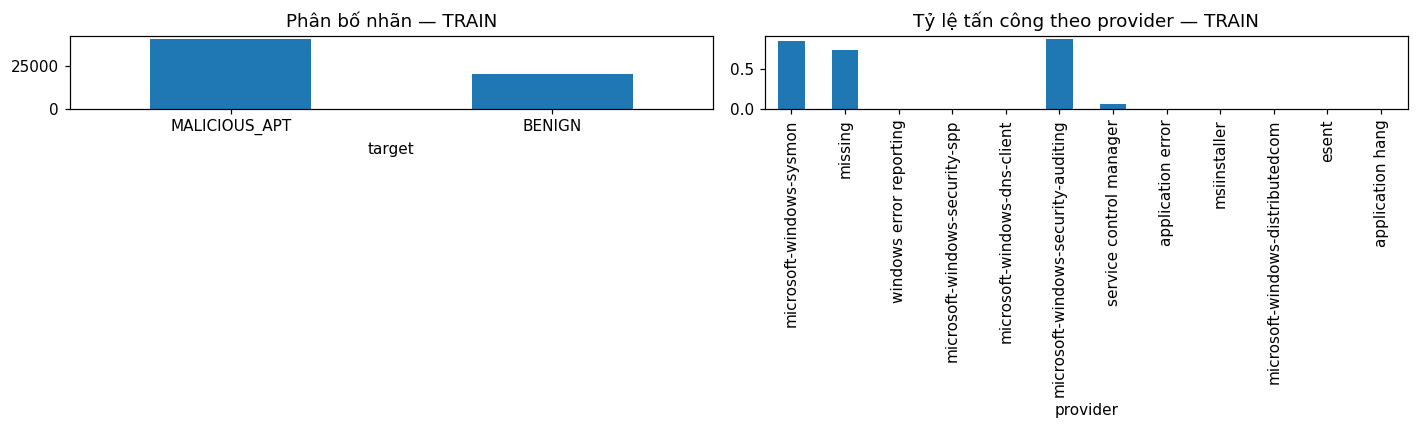

In [5]:
fig,axes=plt.subplots(1,2,figsize=(13,4))
train[TARGET_COLUMN].map({0:'BENIGN',1:'MALICIOUS_APT'}).value_counts().plot.bar(ax=axes[0],rot=0,title='Phân bố nhãn — TRAIN')
train.groupby('provider')[TARGET_COLUMN].agg(['count','mean']).query('count>=100').sort_values('count',ascending=False).head(12)['mean'].plot.bar(ax=axes[1],title='Tỷ lệ tấn công theo provider — TRAIN')
plt.tight_layout(); plt.show()

## 4. Cơ chế Soft Voting và phạm vi triển khai
Các mô hình sinh score lớp MALICIOUS_APT. Soft Voting lấy trung bình có trọng số rồi so với threshold. Ensemble không mặc nhiên tốt hơn mô hình đơn.

In [6]:
display(pd.DataFrame({'Bước':['1','2','3','4'],'Xử lý':['Log chuẩn hóa','Các pipeline dự đoán xác suất','Trung bình theo trọng số CV','So sánh threshold đã khóa']}))

,Bước,Xử lý
0,1,Log chuẩn hóa
1,2,Các pipeline dự đoán xác suất
2,3,Trung bình theo trọng số CV
3,4,So sánh threshold đã khóa


## 5. Tiền xử lý an toàn trong Pipeline
Mỗi mô hình chứa OneHotEncoder riêng được fit bên trong từng fold; không preprocessing toàn bộ dữ liệu trước CV.

In [7]:
factories=teaching_candidate_factories(SEED)
grids=teaching_parameter_grids()
base_names=['decision_tree','naive_bayes','bagging','random_forest','adaboost']
display(pd.DataFrame({'model':base_names,'parameter_grid':[str(grids[name]) for name in base_names]}))

,model,parameter_grid
0,decision_tree,"{'model__max_depth': [12, 20, None], 'model__m..."
1,naive_bayes,"{'model__alpha': [0.1, 1.0, 5.0]}"
2,bagging,"{'model__n_estimators': [50, 100], 'model__max..."
3,random_forest,"{'model__n_estimators': [150, 250], 'model__ma..."
4,adaboost,"{'model__n_estimators': [50, 100], 'model__lea..."


## 6. Dummy baseline
Baseline theo prior là mức tối thiểu ensemble phải vượt qua.

In [8]:
dummy=DummyClassifier(strategy='prior').fit(X_train,y_train)
dummy_pred=dummy.predict(X_validation); dummy_score=dummy.predict_proba(X_validation)[:,1]
display(pd.Series({'accuracy':accuracy_score(y_validation,dummy_pred),'precision':precision_score(y_validation,dummy_pred,zero_division=0),'recall':recall_score(y_validation,dummy_pred,zero_division=0),'f1':f1_score(y_validation,dummy_pred,zero_division=0),'f2':fbeta_score(y_validation,dummy_pred,beta=2,zero_division=0),'roc_auc':roc_auc_score(y_validation,dummy_score),'average_precision':average_precision_score(y_validation,dummy_score)},name='Dummy — Validation').to_frame())

,Dummy — Validation
accuracy,0.548077
precision,0.548077
recall,1.000000
f1,0.708075
f2,0.858434
roc_auc,0.500000
average_precision,0.548077


## 7. Tuning mô hình thành phần bằng 5-Fold chỉ trên Train
Mỗi mô hình được chọn theo CV F2. CV F2 cũng làm trọng số Voting, vì vậy Naive Bayes yếu không còn quyền biểu quyết ngang hàng. Không dùng Validation/Test để tạo trọng số.

In [9]:
estimators=[]; component_rows=[]
for name in base_names:
    component_search=GridSearchCV(factories[name](),grids[name],scoring={'f2':make_scorer(fbeta_score,beta=2,zero_division=0),'roc_auc':'roc_auc','average_precision':'average_precision'},refit='f2',cv=cv,n_jobs=1,return_train_score=True)
    component_search.fit(X_train,y_train,groups=groups)
    estimators.append((name,component_search.best_estimator_))
    component_rows.append({'model':name,'best_params':component_search.best_params_,'cv_f2':float(component_search.best_score_)})
component_table=pd.DataFrame(component_rows).sort_values('cv_f2',ascending=False)
component_weights=[max(next(row['cv_f2'] for row in component_rows if row['model']==name),1e-6) for name in base_names]
display(component_table)
display(pd.DataFrame({'model':base_names,'raw_weight':component_weights,'normalized_weight':np.array(component_weights)/sum(component_weights)}))

,model,best_params,cv_f2
2,bagging,"{'model__max_samples': 0.7, 'model__n_estimato...",0.990357
0,decision_tree,"{'model__max_depth': 20, 'model__min_samples_l...",0.989618
3,random_forest,"{'model__max_depth': 24, 'model__min_samples_l...",0.988639
4,adaboost,"{'model__learning_rate': 1.0, 'model__n_estima...",0.985679
1,naive_bayes,{'model__alpha': 0.1},0.011677


,model,raw_weight,normalized_weight
0,decision_tree,0.989618,0.249527
1,naive_bayes,0.011677,0.002944
2,bagging,0.990357,0.249714
3,random_forest,0.988639,0.249280
4,adaboost,0.985679,0.248534


## 8. Huấn luyện Soft Voting và Validation ở ngưỡng mặc định
Đây là kết quả threshold 0.5 trước khi khóa threshold theo F2.

In [10]:
model=VotingClassifier(estimators=estimators,voting='soft',weights=component_weights,n_jobs=1)
model.fit(X_train,y_train)
validation_score=model.predict_proba(X_validation)[:,1]
validation_default_pred=(validation_score>=0.5).astype(int)
validation_default=pd.Series({'accuracy':accuracy_score(y_validation,validation_default_pred),'precision':precision_score(y_validation,validation_default_pred,zero_division=0),'recall':recall_score(y_validation,validation_default_pred,zero_division=0),'f1':f1_score(y_validation,validation_default_pred,zero_division=0),'f2':fbeta_score(y_validation,validation_default_pred,beta=2,zero_division=0),'roc_auc':roc_auc_score(y_validation,validation_score),'average_precision':average_precision_score(y_validation,validation_score)})
display(validation_default.to_frame('Validation — threshold 0.5'))

,Validation — threshold 0.5
accuracy,0.980670
precision,0.999719
recall,0.965003
f1,0.982054
f2,0.971752
roc_auc,0.999933
average_precision,0.999942


## 9. Chọn và khóa ngưỡng trên Validation
Quét score/phân vị, luôn bổ sung 0.5; chọn F2 cao nhất rồi không chỉnh lại sau khi xem Test.

Score levels: 1,096 | strategy: score quantiles | locked: 0.205125


,threshold,precision,recall,f1,f2
109,0.205125,0.999006,0.999367,0.999186,0.999295
108,0.170369,0.997743,0.999548,0.998645,0.999186
107,0.163777,0.995228,0.999548,0.997383,0.998681
105,0.140347,0.992728,1.000000,0.996351,0.998537
106,0.160226,0.994243,0.999548,0.996888,0.998482
104,0.119988,0.990860,1.000000,0.995409,0.998159
103,0.114818,0.989088,1.000000,0.994514,0.997798
110,0.205799,0.999003,0.996925,0.997963,0.997340
102,0.114202,0.986793,1.000000,0.993352,0.997330
101,0.112229,0.982671,1.000000,0.991260,0.996486


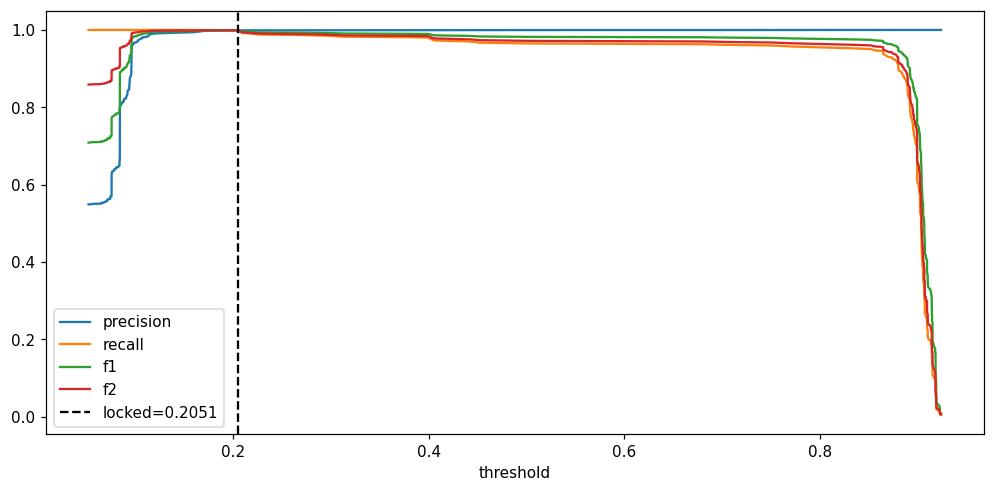

In [11]:
unique_scores=np.unique(validation_score)
if len(unique_scores)<=1000:
    threshold_grid=unique_scores; grid_strategy='all unique scores'
else:
    threshold_grid=np.unique(np.quantile(validation_score,np.linspace(0.001,0.999,999))); grid_strategy='score quantiles'
threshold_grid=np.unique(np.append(threshold_grid,0.5)); threshold_rows=[]
for threshold in threshold_grid:
    p=(validation_score>=threshold).astype(int)
    threshold_rows.append({'threshold':float(threshold),'precision':precision_score(y_validation,p,zero_division=0),'recall':recall_score(y_validation,p,zero_division=0),'f1':f1_score(y_validation,p,zero_division=0),'f2':fbeta_score(y_validation,p,beta=2,zero_division=0)})
threshold_table=pd.DataFrame(threshold_rows).sort_values('threshold')
chosen=threshold_table.sort_values(['f2','recall','precision'],ascending=False).iloc[0]; locked_threshold=float(chosen.threshold)
print(f'Score levels: {len(unique_scores):,} | strategy: {grid_strategy} | locked: {locked_threshold:.6g}')
display(threshold_table.sort_values('f2',ascending=False).head(10))
threshold_table.plot(x='threshold',y=['precision','recall','f1','f2'],figsize=(11,5)); plt.axvline(locked_threshold,color='black',ls='--',label=f'locked={locked_threshold:.4g}'); plt.legend(); plt.show()

## 10. Đánh giá Validation tại ngưỡng khóa
Confusion Matrix, ROC và Precision–Recall dùng score liên tục đúng cách.

,VALIDATION — locked threshold
accuracy,0.999108
precision,0.999006
recall,0.999367
f1,0.999186
f2,0.999295
roc_auc,0.999933
average_precision,0.999942


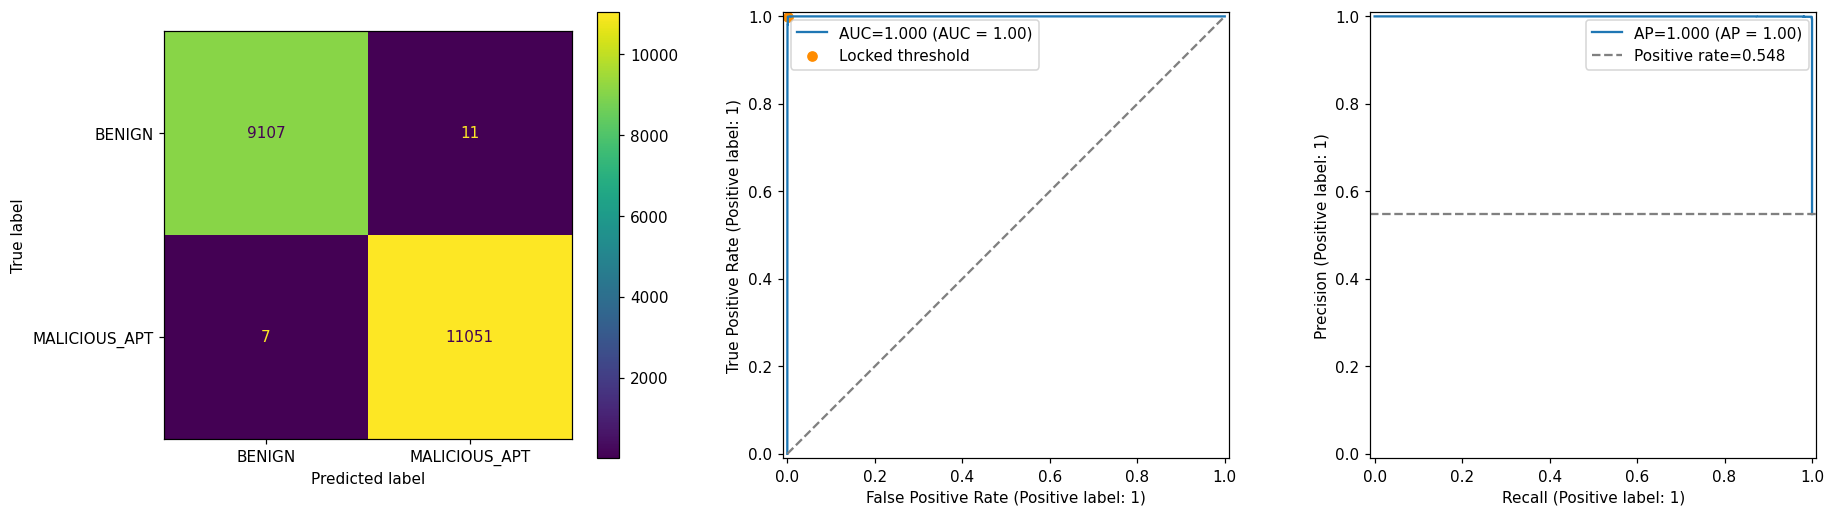

In [12]:
validation_pred=(validation_score>=locked_threshold).astype(int)
validation_result=pd.Series({'accuracy':accuracy_score(y_validation,validation_pred),'precision':precision_score(y_validation,validation_pred,zero_division=0),'recall':recall_score(y_validation,validation_pred,zero_division=0),'f1':f1_score(y_validation,validation_pred,zero_division=0),'f2':fbeta_score(y_validation,validation_pred,beta=2,zero_division=0),'roc_auc':roc_auc_score(y_validation,validation_score),'average_precision':average_precision_score(y_validation,validation_score)})
display(validation_result.to_frame('VALIDATION — locked threshold'))
tn,fp,fn,tp=confusion_matrix(y_validation,validation_pred,labels=[0,1]).ravel()
fig,axes=plt.subplots(1,3,figsize=(17,4.8))
ConfusionMatrixDisplay.from_predictions(y_validation,validation_pred,display_labels=['BENIGN','MALICIOUS_APT'],ax=axes[0])
RocCurveDisplay.from_predictions(y_validation,validation_score,name=f"AUC={validation_result['roc_auc']:.3f}",ax=axes[1]); axes[1].plot([0,1],[0,1],'--',color='gray'); axes[1].scatter([fp/(fp+tn)],[tp/(tp+fn)],color='darkorange',label='Locked threshold'); axes[1].legend()
PrecisionRecallDisplay.from_predictions(y_validation,validation_score,name=f"AP={validation_result['average_precision']:.3f}",ax=axes[2]); axes[2].axhline(float(y_validation.mean()),ls='--',color='gray',label=f'Positive rate={y_validation.mean():.3f}'); axes[2].legend(); plt.tight_layout(); plt.show()

## 11. Đánh giá Test đúng một lần
Mô hình, trọng số và threshold đã khóa. Test chỉ dùng báo cáo cuối.

,TEST
accuracy,0.998589
precision,0.997868
recall,0.999658
f1,0.998763
f2,0.999300
roc_auc,0.999626
average_precision,0.999719


{'TN': 8826, 'FP': 25, 'FN': 4, 'TP': 11703}


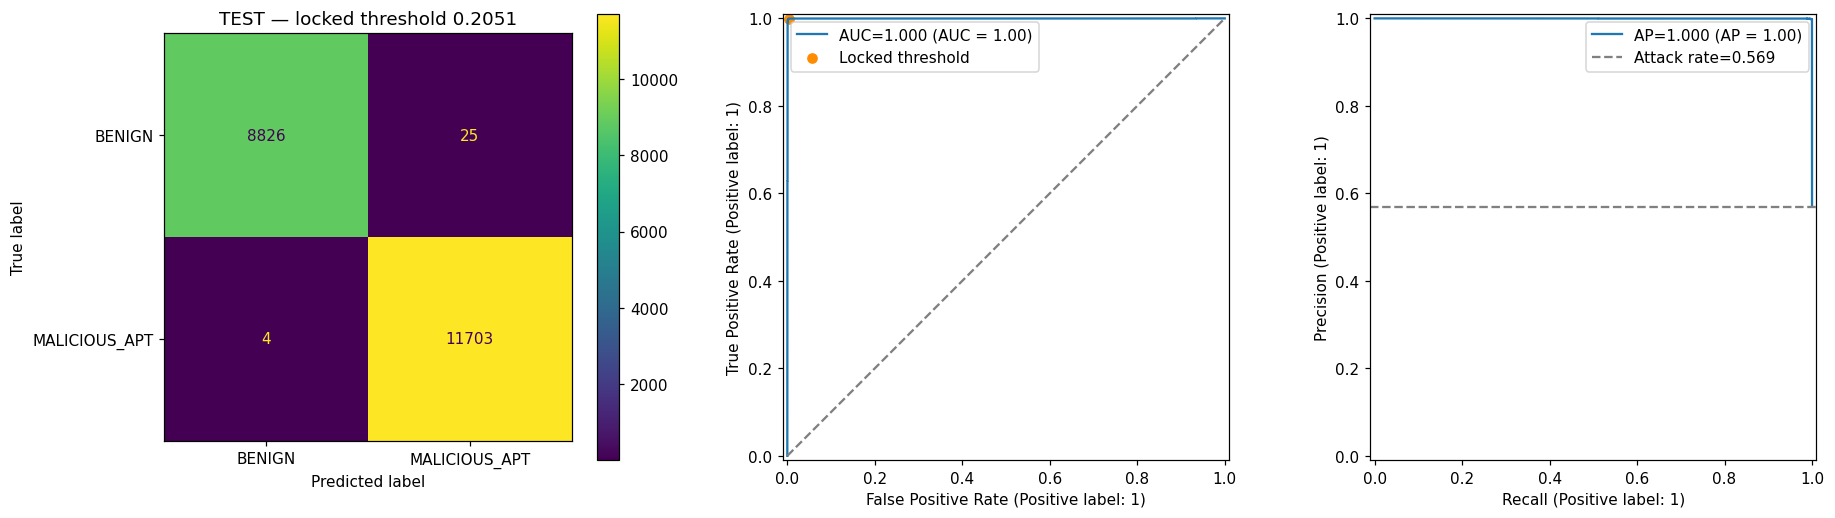

In [13]:
X_test,y_test=test.loc[:,MODEL_FEATURES],test[TARGET_COLUMN]
test_score=model.predict_proba(X_test)[:,1]; test_pred=(test_score>=locked_threshold).astype(int)
test_result=pd.Series({'accuracy':accuracy_score(y_test,test_pred),'precision':precision_score(y_test,test_pred,zero_division=0),'recall':recall_score(y_test,test_pred,zero_division=0),'f1':f1_score(y_test,test_pred,zero_division=0),'f2':fbeta_score(y_test,test_pred,beta=2,zero_division=0),'roc_auc':roc_auc_score(y_test,test_score),'average_precision':average_precision_score(y_test,test_score)})
display(test_result.to_frame('TEST'))
tn,fp,fn,tp=confusion_matrix(y_test,test_pred,labels=[0,1]).ravel(); print({'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp)})
fig,axes=plt.subplots(1,3,figsize=(17,4.8))
ConfusionMatrixDisplay.from_predictions(y_test,test_pred,display_labels=['BENIGN','MALICIOUS_APT'],ax=axes[0]); axes[0].set_title(f'TEST — locked threshold {locked_threshold:.4g}')
RocCurveDisplay.from_predictions(y_test,test_score,name=f"AUC={test_result['roc_auc']:.3f}",ax=axes[1]); axes[1].plot([0,1],[0,1],'--',color='gray'); axes[1].scatter([fp/(fp+tn)],[tp/(tp+fn)],color='darkorange',label='Locked threshold'); axes[1].legend()
PrecisionRecallDisplay.from_predictions(y_test,test_score,name=f"AP={test_result['average_precision']:.3f}",ax=axes[2]); axes[2].axhline(float(y_test.mean()),ls='--',color='gray',label=f'Attack rate={y_test.mean():.3f}'); axes[2].legend(); plt.tight_layout(); plt.show()

## 12. Khoảng bất định bằng bootstrap
Bootstrap Test chỉ mô tả độ bất định, không chọn lại mô hình hoặc threshold.

In [14]:
rng=np.random.default_rng(SEED); boot=[]; y_array=y_test.to_numpy()
for _ in range(300):
    idx=rng.integers(0,len(y_array),len(y_array))
    if np.unique(y_array[idx]).size<2: continue
    boot.append({'f2':fbeta_score(y_array[idx],test_pred[idx],beta=2,zero_division=0),'roc_auc':roc_auc_score(y_array[idx],test_score[idx]),'average_precision':average_precision_score(y_array[idx],test_score[idx])})
boot=pd.DataFrame(boot)
display(pd.DataFrame({'estimate':test_result[['f2','roc_auc','average_precision']],'ci_2.5%':boot.quantile(.025),'ci_97.5%':boot.quantile(.975)}))

,estimate,ci_2.5%,ci_97.5%
f2,0.999300,0.998956,0.999585
roc_auc,0.999626,0.999253,0.999891
average_precision,0.999719,0.999464,0.999907


## 13. Lưu kết quả thực nghiệm
Lưu model, trọng số, threshold, split hash và tách rõ Validation mặc định/đã khóa với Test đã khóa.

In [15]:
experiment_dir=ROOT/'reports'/'notebook_experiments'; experiment_dir.mkdir(parents=True,exist_ok=True)
slug='07_soft_voting'; joblib.dump(model,experiment_dir/f'{slug}.joblib')
record={'schema_version':2,'model':'soft_voting','base_models':base_names,'component_cv':component_rows,'weights':dict(zip(base_names,map(float,component_weights))),'locked_threshold':locked_threshold,'split_hash':split_hash,'validation_default_threshold':{k:float(v) for k,v in validation_default.items()},'validation_locked_threshold':{k:float(v) for k,v in validation_result.items()},'test_locked_threshold':{k:float(v) for k,v in test_result.items()}}
(experiment_dir/f'{slug}.json').write_text(json.dumps(record,indent=2),encoding='utf-8'); record

{'schema_version': 2,
 'model': 'soft_voting',
 'base_models': ['decision_tree',
  'naive_bayes',
  'bagging',
  'random_forest',
  'adaboost'],
 'component_cv': [{'model': 'decision_tree',
   'best_params': {'model__max_depth': 20, 'model__min_samples_leaf': 3},
   'cv_f2': 0.9896177585259174},
  {'model': 'naive_bayes',
   'best_params': {'model__alpha': 0.1},
   'cv_f2': 0.01167714824593263},
  {'model': 'bagging',
   'best_params': {'model__max_samples': 0.7, 'model__n_estimators': 50},
   'cv_f2': 0.9903572494654822},
  {'model': 'random_forest',
   'best_params': {'model__max_depth': 24,
    'model__min_samples_leaf': 3,
    'model__n_estimators': 150},
   'cv_f2': 0.988638943885882},
  {'model': 'adaboost',
   'best_params': {'model__learning_rate': 1.0, 'model__n_estimators': 100},
   'cv_f2': 0.9856794173813773}],
 'weights': {'decision_tree': 0.9896177585259174,
  'naive_bayes': 0.01167714824593263,
  'bagging': 0.9903572494654822,
  'random_forest': 0.988638943885882,
  'ada

## 14. Kết luận và giới hạn
Chỉ chọn Voting nếu Validation F2 tốt hơn mô hình đơn theo cùng giao thức. Nhãn rule-derived, dữ liệu Windows APT mô phỏng và Validation chỉ có hai nhóm ngày; cần external validation bằng log Wazuh thật trước production.

## Cập nhật pipeline dữ liệu hợp nhất

Notebook này thuộc bộ thí nghiệm SecuraAI mới. Có hai tầng kết quả cần phân biệt:

- **Thí nghiệm giảng dạy 00–10:** so sánh thuật toán trên cùng split Windows-APT để bảo đảm công bằng.
- **Baseline hợp nhất theo từng event:** Windows-APT 2025 + RADAR + log Wazuh đã bộc lộ domain shift khi test trực tiếp.
- **Ứng viên temporal:** dùng `event_family`, `event_type` và thống kê cửa sổ 5 phút; vẫn chỉ chạy shadow.

RADAR bổ sung ground truth ransomware/Sysmon theo từng mẫu thực thi. Log Wazuh hiện tại chỉ là kiểm thử lab và weak-benign; không được trình bày như bằng chứng production. Test, threshold và dữ liệu ngoài miền được giữ tách biệt để giảm leakage.

In [16]:
import pandas as pd

combined_artifact_dir = ROOT / 'artifacts-combined-candidate'
combined_metadata_path = combined_artifact_dir / 'model_metadata.json'
combined_source_report_path = ROOT / 'reports' / 'combined_candidate_by_source.json'
temporal_artifact_dir = ROOT / 'artifacts-temporal-candidate'
temporal_metadata_path = temporal_artifact_dir / 'model_metadata.json'

if combined_metadata_path.exists():
    combined_metadata = json.loads(combined_metadata_path.read_text(encoding='utf-8'))
    display(pd.DataFrame({
        'value': [
            combined_metadata['selectedModel'],
            combined_metadata['lockedThreshold'],
            ', '.join(combined_metadata['datasets']),
            combined_metadata['test']['f2'],
            combined_metadata['test']['precision'],
            combined_metadata['test']['recall'],
        ]
    }, index=['selected_model','locked_threshold','datasets','combined_test_f2','combined_test_precision','combined_test_recall']))
else:
    print('Chưa có artifacts-combined-candidate. Chạy scripts/train_combined_candidate.py trước.')

if temporal_metadata_path.exists():
    temporal_metadata = json.loads(temporal_metadata_path.read_text(encoding='utf-8'))
    display(pd.DataFrame({
        'value': [
            temporal_metadata['selectedModel'], temporal_metadata['lockedThreshold'],
            temporal_metadata['validation']['f2'], temporal_metadata['test']['f2'],
            temporal_metadata['test']['falsePositiveRate'], temporal_metadata['status'],
        ]
    }, index=['temporal_model','temporal_threshold','validation_f2','test_f2','test_fpr','status']))
else:
    print('Chưa có artifacts-temporal-candidate. Chạy scripts/train_temporal_candidate.py trước.')


,value
selected_model,logistic_regression
locked_threshold,0.442104
datasets,"Windows-APT 2025 v4, RADAR v0.0.1-beta"
combined_test_f2,0.994966
combined_test_precision,0.990039
combined_test_recall,0.996205


,value
temporal_model,random_forest
temporal_threshold,0.735188
validation_f2,0.866388
test_f2,0.882957
test_fpr,0.039261
status,EXPERIMENTAL_SYNTHETIC_ONLY
